# Two Hidden Layers

> **Overview.** The growing LTUs of 06 in two hidden layers, on a target network with two hidden layers: do depth-2
> LTUs find the target's depth-2 features, which are built on its depth-1 features?

The step after `06_multiple_outputs.ipynb`, toward the deep sparse target network, whose units read units below them.
Half the LTUs have depth 1 and half depth 2, and an LTU can read anything of lower depth (inputs have depth 0), so a
depth-2 LTU grows over the inputs and the depth-1 LTUs.

**Problem.** $N = 1000$ standard normal inputs. Two hidden layers of 8 target LTUs each, with random $\pm 1$ weights
and threshold 0, giving $\pm 1$: a depth-1 target LTU reads 10 inputs drawn at random, and a depth-2 target LTU reads 5
inputs and 5 depth-1 target LTUs drawn at random. 10 outputs, each reading 2 inputs and 2 target LTUs of each depth drawn
at random, with random weights $\pm 1 / \sqrt{6}$, plus $N(0, 0.1^2)$ noise. The best possible RMSE is 0.1 (dotted line). Each seed
has its own target network.

**Learner.** As in `06_multiple_outputs.ipynb`, with 16 LTUs of depth 1 and 16 of depth 2: the linear learner (every
output reads every input), a bias, and the LTUs (sigmoid derivative backward), standardized online and computed depth
by depth; network Autostep (`squared_inputs`, initial step-size $10^{-4}$, meta step-size 0.02, $\tau = 10^4$). Every LTU
feeds every output, with a shadow weight, +1 and -1 alternately, on one output drawn at random. The linear learner
learns alone for the first 100k steps; then the LTUs of both depths are added, and everything learns for 2M more steps. An
LTU treats every source it may read alike, inputs and depth-1 LTUs: when added or rewired it reads 1 to 20 of them,
drawn without replacement with probability proportional to the square of its shadow output's weight on each (for an
input, the linear learner's weight), with fast learning, its weights' signs those of its shadow weight times those
output weights. Growth's candidates are
the sources an LTU may read but does not: the inputs, and for depth 2 also the depth-1 LTUs. Search replaces the 4 LTUs
with the smallest sum of outgoing weight magnitudes (to the outputs and to depth-2 LTUs); the connections from a
replaced depth-1 LTU to depth-2 LTUs are cut. Before that, a depth-2 LTU with less than 10% of its input weight
magnitude on depth-1 LTUs acts as a depth-1 LTU, so it moves to depth 1: of those, the one with the largest sum of
outgoing weight magnitudes swaps slots with the depth-1 LTU with the smallest, if that one's is smaller, and loses its
connections from depth-1 LTUs; the displaced LTU, now at depth 2, is among those replaced.

**Runs.** 5 seeds per configuration; the same seed gives every run the same target network and samples. *Growth with
fast search every 10k steps* (proposed). *Growth without search* (proposed). *Fully connected* (baseline): the linear
learner, depth-1 LTUs reading every input and depth-2 LTUs reading every input and every depth-1 LTU, all learning from
the first step, with LeCun uniform input weights over their fan-in and no fast learning, growth or search. *LTUs wired
like the target network* (reference): each pair of depth-1 LTUs reads one depth-1 target LTU's inputs, and each pair of
depth-2 LTUs reads one depth-2 target LTU's inputs and the depth-1 LTUs wired like its depth-1 target LTUs (weights
starting at 0), with shadow weights on an output that reads that target LTU (any output if none does), fast learning,
and no search or growth. *Linear learner* (baseline): no LTUs. Curves are the mean over seeds of the RMSE over the 10
outputs, averaged over windows of 1k steps; final performance is the RMSE over the last 10% of steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_PER_DEPTH = 8                      # target LTUs per hidden layer
N_SOURCES = 10                       # sources each target LTU reads, split equally over the depths below it
N_OUTPUTS = 10
OUTPUT_FAN_IN = 6                    # sources each output reads, split equally over the inputs and the 2 hidden layers
NOISE_STD = 0.1                      # observation noise on each output: the RMSE floor

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32                          # hidden LTUs, the first half of depth 1 and the second of depth 2
MAX_FAN_IN = 20                      # LTUs with sampled inputs read 1 to MAX_FAN_IN of them
REPLACED = 4                         # LTUs replaced at each search step, those with the smallest sum of |outgoing weights|
FAST_STEP_SIZE = 3e-2                # initial step-size of the input weights of LTUs that learn fast
GROW_Z = 6.0                         # an LTU connects a source whose gradient sum is this many RMS above the rest
FLAT_SHARE = 0.1                     # a depth-2 LTU with less than this share of its input |weights| on depth-1 LTUs
                                     # acts as a depth-1 LTU

# --- Experiment ---
LINEAR_STEPS = 100_000               # the linear learner learns alone for this many steps, then the LTUs are added
NUM_STEPS = 2_000_000                # steps after the LTUs are added
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps


## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (2 * N_PER_DEPTH, N_INPUTS + 2 * N_PER_DEPTH): the target LTUs' weights over [inputs,
                                # target LTUs], +-1 on the sources they read, 0 elsewhere; the first N_PER_DEPTH have depth 1
    out: jax.Array              # (N_OUTPUTS, N_INPUTS + 2 * N_PER_DEPTH): the outputs' weights over [inputs, target
                                # LTUs], +-1/sqrt(OUTPUT_FAN_IN) on the sources they read


def make_target(key):
    # A target network: each depth-1 target LTU reads N_SOURCES inputs, each depth-2 one N_SOURCES / 2 inputs and
    # N_SOURCES / 2 depth-1 target LTUs, and each output OUTPUT_FAN_IN / 3 inputs and target LTUs of each depth, all
    # drawn at random, with random +-1 weights (the outputs' scaled by 1 / sqrt(OUTPUT_FAN_IN)).
    k = jax.random.split(key, 8)
    n = N_PER_DEPTH
    pick = lambda key, shape, count: jnp.argsort(jnp.argsort(jax.random.uniform(key, shape))) < count  # per row
    inputs = jnp.concatenate([pick(k[0], (n, N_INPUTS), N_SOURCES), pick(k[1], (n, N_INPUTS), N_SOURCES // 2)])
    hidden = jnp.zeros((2 * n, 2 * n), bool).at[n:, :n].set(pick(k[2], (n, n), N_SOURCES // 2))
    w = jax.random.rademacher(k[3], (2 * n, N_INPUTS + 2 * n), dtype=float) * jnp.concatenate([inputs, hidden], 1)
    reads = jnp.concatenate([pick(k[7], (N_OUTPUTS, N_INPUTS), OUTPUT_FAN_IN // 3),
                             pick(k[4], (N_OUTPUTS, n), OUTPUT_FAN_IN // 3), pick(k[5], (N_OUTPUTS, n), OUTPUT_FAN_IN // 3)], 1)
    out = jax.random.rademacher(k[6], reads.shape, dtype=float) * reads / np.sqrt(OUTPUT_FAN_IN)
    return Target(w, out)


def sample(target, key):
    # One input and its noisy targets, the target LTUs computed depth by depth.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    s = jnp.zeros(2 * N_PER_DEPTH)
    for rows in (slice(0, N_PER_DEPTH), slice(N_PER_DEPTH, None)):
        s = s.at[rows].set(jnp.where(target.w[rows] @ jnp.concatenate([x, s]) > 0, 1.0, -1.0))
    return x, target.out @ jnp.concatenate([x, s]) + NOISE_STD * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped (units,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


HALF = N_LTUS // 2
DEPTHS = (slice(0, HALF), slice(HALF, N_LTUS))   # the hidden units of depth 1 and of depth 2
# LOWER[u, j]: whether hidden unit u may read source j of [inputs, hidden units, 1]: every input and the bias, and the
# hidden units of lower depth.
LOWER = jnp.ones((N_LTUS, N_INPUTS + N_LTUS + 1), bool).at[:, N_INPUTS:-1].set(
    (jnp.arange(N_LTUS) >= HALF)[:, None] & (jnp.arange(N_LTUS) < HALF)[None])


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, hidden units, 1 (the bias)], of which they read those in
    # `reads`; w['output'] is the outputs' weights over [inputs (the linear learner), the hidden units, 1]. `mask` says
    # which of the outputs' connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + N_LTUS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each hidden unit's shadow weight, +-1 on one output, 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS + N_LTUS): sum of dL/dz * source since each unit's last new connection


def active(net):
    # Which slots hold a hidden unit.
    return jnp.any(net.shadow != 0, 0)


def shadow_output_weights(net):
    # Shaped like w['hidden']: each hidden unit's shadow weight times its shadow output's weights on the sources it may
    # read (for an input, the linear learner's weight), 0 elsewhere and on the bias.
    return (net.shadow.T @ net.w['output']).at[:, -1].set(0.0) * LOWER


def init_net(key, target, units, sampled, dense=False):
    # `units` hidden units (the rest of the N_LTUS slots left empty), each pair of a depth wired like one target LTU of
    # that depth in turn, reading its inputs and the depth-1 units wired like its depth-1 target LTUs (every source it
    # may read if dense) and the bias, with LeCun uniform weights over their fan-in; their shadow weights +1 and -1
    # alternately, each on an output drawn at random among those that read its target LTU (among all outputs if sampled
    # or dense, or if none does); every other weight at 0.
    w_key, out_key = jax.random.split(key)
    slot = jnp.arange(N_LTUS)
    assigned = slot // HALF * N_PER_DEPTH + slot % HALF // 2 % N_PER_DEPTH   # the target LTU each unit is wired like
    target_reads = target.w[assigned] != 0
    wired = jnp.concatenate([target_reads[:, :N_INPUTS], target_reads[:, N_INPUTS:][:, assigned],
                             jnp.ones((N_LTUS, 1), bool)], 1)
    reads = LOWER if dense else wired & LOWER
    fan_in = reads[:, :-1].sum(1, keepdims=True)
    readers = (target.out[:, N_INPUTS + assigned] != 0) | sampled | dense
    readers = readers | ~readers.any(0)
    shadow_out = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    sign = jnp.where(slot < units, jnp.where(slot % 2 == 0, 1.0, -1.0), 0.0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == shadow_out) * sign
    mask = jnp.ones((N_OUTPUTS, N_INPUTS + N_LTUS + 1), bool).at[:, N_INPUTS:-1].set(False)
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, reads, mask, OPTIMIZER.init(w), stats, shadow, jnp.zeros((N_LTUS, N_INPUTS + N_LTUS)))


def rewire(net, key, replaced):
    # The `replaced` hidden units (a mask over slots) each read 1 to MAX_FAN_IN sources (uniform) and the bias, the
    # sources, inputs and lower-depth units alike, drawn without replacement with probability proportional to the
    # square of their shadow output's weight on them (Gumbel top-k), with fresh LeCun uniform weights over their
    # fan-in, output weights at 0, and fresh statistics, Autostep state and gradient sums; the other units' connections
    # from them are cut. Each keeps its shadow weight.
    fan_key, draw_key, w_key = jax.random.split(key, 3)
    fan_in = jax.random.randint(fan_key, (N_LTUS, 1), 1, MAX_FAN_IN + 1)
    cut = jnp.zeros_like(net.reads).at[:, N_INPUTS:-1].set(replaced[None])   # connections from the replaced units
    scores = (jnp.log(jnp.where(cut, 0.0, shadow_output_weights(net))[:, :-1] ** 2)
              + jax.random.gumbel(draw_key, (N_LTUS, N_INPUTS + N_LTUS)))
    reads = jnp.append(jnp.argsort(jnp.argsort(-scores)) < fan_in, jnp.ones((N_LTUS, 1), bool), axis=1)
    hidden = jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / fan_in) * reads
    changed = replaced[:, None] | cut
    where = {'hidden': changed,
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    w = reset(net.w, {'hidden': hidden.at[:, -1].set(0.0), 'output': jnp.zeros_like(net.w['output'])})
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    opt = net.opt._replace(beta=reset(net.opt.beta, jax.tree.map(lambda a: a + net.opt.init_beta, zeros)),
                           h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=w, reads=jnp.where(changed, reads, net.reads), opt=opt, stats=stats,
                        candidates=jnp.where(changed[:, :-1], 0.0, net.candidates))


def speed_up(net, replaced):
    # The `replaced` hidden units' weights keep their magnitudes but take the signs of their shadow weight times their
    # shadow output's weights on those sources (0 where that weight is 0), and the step-sizes of all their weights but
    # the bias's start at FAST_STEP_SIZE.
    sources = net.reads.at[:, -1].set(False) & replaced[:, None]
    hidden = jnp.where(sources, jnp.abs(net.w['hidden']) * jnp.sign(shadow_output_weights(net)), net.w['hidden'])
    beta = jnp.where(sources, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': hidden}, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def grow(net):
    # Each hidden unit whose largest gradient sum, over the sources it may read but does not, is more than GROW_Z times
    # their root mean square connects that source, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = LOWER[:, :-1] & ~net.reads[:, :-1]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    best = jnp.argmax(sums, 1)
    grows = (jnp.max(sums, 1) > GROW_Z * rms) & active(net)
    new = (jnp.arange(N_INPUTS + N_LTUS + 1) == best[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, the hidden units computed
    # depth by depth, each shadow weight standing in for its hidden unit's weight to that output in the backward pass
    # while the real one is smaller in magnitude, the hidden units' other weights used as they are. Returns the new
    # network and the squared error on this sample averaged over the outputs, before learning from it, and adds
    # dL/dz * source to each hidden unit's gradient sums. `probe` is zero; its gradients are the error arriving at each
    # hidden unit and dL/dz.

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}
        a, means, hs = jnp.zeros(N_LTUS), [], []
        for rows in DEPTHS:
            b = ltu(w['hidden'][rows] @ jnp.concatenate([x, a, jnp.ones(1)]) + probe[1][rows])
            mean = net.stats.hidden_mean[rows] + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean[rows])
            h = standardize(b, mean, net.stats.error_mean[rows], net.stats.error_h_mean[rows])
            a = a.at[rows].set(h + probe[0][rows])
            means.append(mean)
            hs.append(jax.lax.stop_gradient(h))
        source = jax.lax.stop_gradient(jnp.concatenate([x, a, jnp.ones(1)]))
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w) * net.mask[:, N_INPUTS:-1]
        through_back = jax.lax.stop_gradient(back) @ a
        prediction = w['output'] @ source + through_back - jax.lax.stop_gradient(through_back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (source, jnp.concatenate(hs), jnp.concatenate(means))

    (loss, (source, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    error, dz = error
    sources = {'hidden': source[None] * net.reads, 'output': source[None] * net.mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * source[:-1]), 2 * loss / N_OUTPUTS

## Training

In [5]:
def swap(net, i, j):
    # Slots i and j exchange their units; the unit arriving at depth-1 slot i loses its connections from hidden units.
    perm = jnp.arange(N_LTUS).at[i].set(j).at[j].set(i)
    cols = jnp.concatenate([jnp.arange(N_INPUTS), N_INPUTS + perm, jnp.array([N_INPUTS + N_LTUS])])
    tree = lambda t: {'hidden': t['hidden'][perm][:, cols], 'output': t['output'][:, cols]}
    net = net._replace(w=tree(net.w), reads=net.reads[perm][:, cols], mask=net.mask[:, cols],
                       opt=net.opt._replace(beta=tree(net.opt.beta), h=tree(net.opt.h), v=tree(net.opt.v)),
                       stats=Stats(*(a[perm] for a in net.stats)), shadow=net.shadow[:, perm],
                       candidates=net.candidates[perm][:, cols[:-1]])
    cut = jnp.zeros_like(net.reads).at[i, N_INPUTS:-1].set(True)
    zero = lambda t: {**t, 'hidden': jnp.where(cut, 0.0, t['hidden'])}
    beta = jnp.where(cut, net.opt.init_beta, net.opt.beta['hidden'])
    return net._replace(w=zero(net.w), reads=net.reads & ~cut,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}, h=zero(net.opt.h), v=zero(net.opt.v)))


def train(net, key, target, sampled, period, fast, grows, add_step, num_steps):
    # num_steps online network-Autostep steps on samples from `target`, the hidden units added at add_step (first
    # rewired if sampled), and every `period` steps after that (never if period is 0) the REPLACED of them with the
    # smallest sum of |outgoing weights| rewired, after the strongest depth-2 unit acting as a depth-1 unit (if any)
    # swaps slots with the weakest depth-1 unit, if weaker; every unit added or rewired sped up if fast, and every WINDOW
    # steps after the units are added, each grows if grows (before any rewiring). Returns each window's mean squared error.
    wire_key, key = jax.random.split(key)

    def one_step(net, inputs):
        step, key = inputs
        x, y = sample(target, key)
        net = net._replace(mask=net.mask.at[:, N_INPUTS:-1].set((step >= add_step) & active(net)))
        return learn(net, x, y)

    def start(net, key, replaced, rewired):
        # The replaced units rewired (if rewired) and sped up (if fast).
        net = jax.tree.map(lambda a, b: jnp.where(rewired, a, b), rewire(net, key, replaced), net)
        return jax.tree.map(lambda a, b: jnp.where(fast, a, b), speed_up(net, replaced), net)

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        since_added = (index + 1) * WINDOW - add_step
        net = jax.tree.map(lambda a, b: jnp.where(grows & (since_added > 0), a, b), grow(net), net)
        due = (period > 0) & (since_added > 0) & (since_added % jnp.maximum(period, 1) == 0)
        outgoing = (jnp.abs(net.w['output'][:, N_INPUTS:-1]).sum(0)
                    + jnp.abs(net.w['hidden'][:, N_INPUTS:-1] * net.reads[:, N_INPUTS:-1]).sum(0))
        links = jnp.abs(net.w['hidden'][:, :-1]) * net.reads[:, :-1]
        flat = (jnp.arange(N_LTUS) >= HALF) & active(net) & (links[:, N_INPUTS:].sum(1) < FLAT_SHARE * links.sum(1))
        mover = jnp.argmax(jnp.where(flat, outgoing, -jnp.inf))
        weak = jnp.argmin(jnp.where(active(net) & (jnp.arange(N_LTUS) < HALF), outgoing, jnp.inf))
        moved = due & flat.any() & (outgoing[mover] > outgoing[weak])
        net = jax.tree.map(lambda a, b: jnp.where(moved, a, b), swap(net, weak, mover), net)
        outgoing = jnp.where(moved, outgoing.at[weak].set(outgoing[mover]).at[mover].set(-1.0), outgoing)
        weakest = jnp.argsort(jnp.where(active(net), outgoing, jnp.inf))[:REPLACED]
        searched = start(net, jax.random.fold_in(wire_key, index), jnp.zeros(N_LTUS, bool).at[weakest].set(True), True)
        return jax.tree.map(lambda a, b: jnp.where(due, a, b), searched, net), mse.mean()

    n, added = num_steps // WINDOW, add_step // WINDOW
    index, keys = jnp.arange(n), jax.random.split(key, n)
    net, before = jax.lax.scan(window, net, (index[:added], keys[:added]))
    net = start(net, wire_key, active(net), sampled)
    return jnp.concatenate([before, jax.lax.scan(window, net, (index[added:], keys[added:]))[1]])


def run(configs, dense=False):
    # Each (units, sampled, period, fast, grows) of configs: `units` hidden LTUs reading sampled inputs if sampled,
    # searched every `period` steps (0: never), and wired like the target network otherwise (no LTUs: the linear
    # learner alone), learning fast if fast and growing if grows, each on N_SEEDS seeds, vmapped together. Seed s gives every
    # run the same target network and samples. Returns {config: the RMSE of each window from step 1, shaped (seed,
    # window)}. If dense, every LTU reads every source it may read and learns from the first step.
    units, sampled, period, fast, grows, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs
                                                                             for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2))
    nets = jax.vmap(lambda k, t, u, s: init_net(k, t, u, s, dense))(keys(0), targets, units, sampled)
    train_all = jax.jit(jax.vmap(lambda n, k, t, s, p, f, g: train(n, k, t, s, p, f, g, 0 if dense else LINEAR_STEPS,
                                                                   LINEAR_STEPS + NUM_STEPS)))
    mse = train_all(nets, keys(1), targets, sampled, period, fast, grows)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [6]:
LINEAR, DENSE = (0, False, 0, False, False), (N_LTUS, False, 0, False, False)
GROWTH, GROWTH_NO_SEARCH = (N_LTUS, True, PERIOD, True, True), (N_LTUS, True, 0, True, True)
REFERENCE = (N_LTUS, False, 0, True, False)
started = perf_counter()
rmse = run([LINEAR, DENSE], dense=True) | run([GROWTH, GROWTH_NO_SEARCH, REFERENCE])
print(f'{len(rmse) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

25 runs in 303s


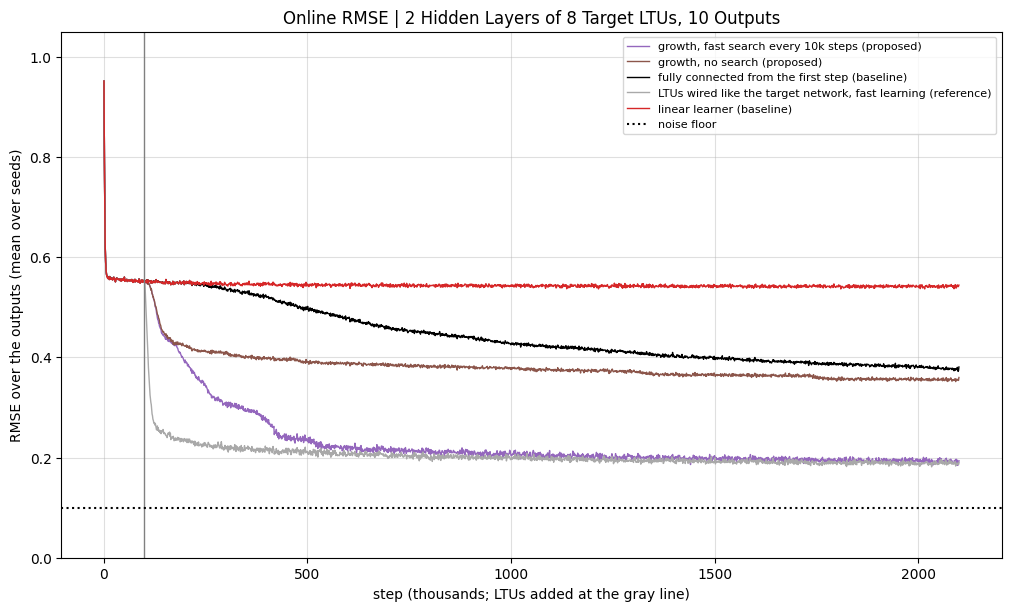

In [7]:
STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // WINDOW) + 1) * WINDOW
METHODS = {f'growth, fast search every {PERIOD // 1000}k steps (proposed)': (GROWTH, 'tab:purple'),
           'growth, no search (proposed)': (GROWTH_NO_SEARCH, 'tab:brown'),
           'fully connected from the first step (baseline)': (DENSE, 'black'),
           'LTUs wired like the target network, fast learning (reference)': (REFERENCE, 'darkgray'),
           'linear learner (baseline)': (LINEAR, 'tab:red')}

fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
for label, (config, color) in METHODS.items():
    ax.plot(STEPS / 1000, rmse[config].mean(0), color=color, lw=1, label=label)
ax.axvline(LINEAR_STEPS / 1000, color='gray', lw=1)
ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
ax.set(xlabel='step (thousands; LTUs added at the gray line)', ylabel='RMSE over the outputs (mean over seeds)',
       ylim=(0, 1.05), title=f'Online RMSE | 2 Hidden Layers of {N_PER_DEPTH} Target LTUs, {N_OUTPUTS} Outputs')
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
plt.show()

## Results

5 seeds per configuration. The notebook takes about 5 minutes.

- **Growth with search reaches the reference**: RMSE 0.193 at the end, against 0.189 for LTUs wired like the target
  network and 0.54 for the linear learner (growth without search 0.36; fully connected 0.38, still falling).
- **It is slow**: it reaches 0.25 a median 325k steps after the LTUs are added (135k to 842k), the reference 27k.
- **What it finds** (checked separately, at the end; a target LTU is *found* when some LTU's output has |correlation|
  above 0.9 with it): 97% of the depth-1 target LTUs and 75% of the depth-2 ones (the reference: 100% and 82%). 11% of
  depth-2 LTUs copy a depth-1 target LTU, mostly by relaying the depth-1 LTU that holds it. Of the 10 depth-2 target
  LTUs not found, 3 are read by no output, and 2 only by outputs that are no depth-2 LTU's shadow output, so seeds never
  draw from their sources.